In [1]:
import numpy as np
import scipy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

In [2]:
def super_gaussian_envelope(
    shape=(401, 401),
    a=70.0,
    b=40.0,
    angle_deg=0.0,
    p=2.0,
    intensity=1.0,
):
    """
    Génère une enveloppe d'intensité super-gaussienne elliptique centrée.

    Parameters
    ----------
    shape : tuple[int, int]
        Dimensions (hauteur, largeur).
    a, b : float
        Demi-axes en pixels au niveau intensity * exp(-2).
    angle_deg : float
        Orientation antihoraire en degrés.
    p : float
        Ordre du profil : 1 = gaussien, > 1 = super-gaussien.
    intensity : float
        Intensité au centre, en unités arbitraires.

    Returns
    -------
    I : ndarray, shape (hauteur, largeur)
        Carte d'intensité.
    x, y : ndarray
        Coordonnées des centres des pixels, relativement au centre.
    """
    if len(shape) != 2 or any(
        not isinstance(n, (int, np.integer)) or n <= 0
        for n in shape
    ):
        raise ValueError("shape doit contenir deux entiers strictement positifs.")

    values = np.asarray([a, b, angle_deg, p, intensity], dtype=float)
    if not np.all(np.isfinite(values)):
        raise ValueError("Tous les paramètres doivent être finis.")

    if a <= 0 or b <= 0:
        raise ValueError("a et b doivent être strictement positifs.")
    if p < 1:
        raise ValueError("p doit être supérieur ou égal à 1.")
    if intensity < 0:
        raise ValueError("intensity doit être positive ou nulle.")

    height, width = shape

    x = np.arange(width, dtype=float) - (width - 1) / 2
    y = np.arange(height, dtype=float) - (height - 1) / 2
    X, Y = np.meshgrid(x, y)

    theta = np.deg2rad(angle_deg)
    X_rot = X * np.cos(theta) + Y * np.sin(theta)
    Y_rot = -X * np.sin(theta) + Y * np.cos(theta)

    radius_squared = (X_rot / a) ** 2 + (Y_rot / b) ** 2

    with np.errstate(over="ignore"):
        I = intensity * np.exp(-2.0 * radius_squared ** p)

    return I, x, y

In [3]:
LASER_WAVELENGTH_NM = 532  # Étiquette ; pas de conversion spectrale.
LASER_DISPLAY_COLOR = "#00ff00"

laser_cmap = LinearSegmentedColormap.from_list(
    "laser_green",
    ["black", LASER_DISPLAY_COLOR],
)


def plot_envelope(I, x, y, display_max=1.0):
    """Affiche la carte et une coupe horizontale à y = 0."""
    if not np.isfinite(display_max) or display_max <= 0:
        raise ValueError("display_max doit être strictement positif et fini.")

    height, width = I.shape

    # Coupe exacte à y = 0 pour une hauteur impaire ;
    # moyenne des deux lignes centrales pour une hauteur paire.
    if height % 2:
        profile = I[height // 2, :]
        profile_label = "Coupe horizontale à y = 0"
    else:
        profile = I[height // 2 - 1:height // 2 + 1, :].mean(axis=0)
        profile_label = "Coupe centrale approchée (moyenne de deux lignes)"

    extent = (
        x[0] - 0.5, x[-1] + 0.5,
        y[0] - 0.5, y[-1] + 0.5,
    )

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12, 4.8),
        constrained_layout=True,
    )

    image = axes[0].imshow(
        I,
        origin="lower",
        extent=extent,
        cmap=laser_cmap,
        vmin=0,
        vmax=display_max,
        interpolation="nearest",
        aspect="equal",
    )

    axes[0].axhline(
        0, color="white", linestyle="--", linewidth=0.8, alpha=0.6
    )
    axes[0].set(
        title=f"Enveloppe — affichage vert ({LASER_WAVELENGTH_NM} nm)",
        xlabel="x (pixels)",
        ylabel="y (pixels)",
    )

    fig.colorbar(
        image,
        ax=axes[0],
        label="Intensité (u.a.)",
        extend="max" if I.max() > display_max else "neither",
    )

    axes[1].plot(x, profile, color="forestgreen", linewidth=2)
    axes[1].set(
        title=profile_label,
        xlabel="x (pixels)",
        ylabel="Intensité (u.a.)",
        xlim=(x[0], x[-1]),
        ylim=(0, 1.05 * max(display_max, float(I.max()))),
    )
    axes[1].grid(alpha=0.3)

    plt.show()

    return fig, axes

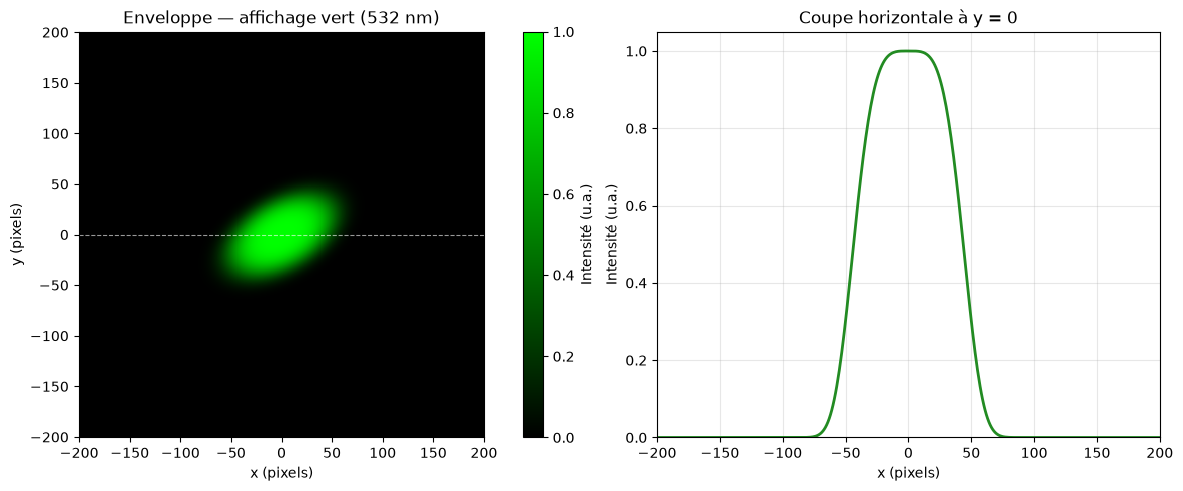

In [4]:
params = {
    "shape": (401, 401),
    "a": 70.0,
    "b": 40.0,
    "angle_deg": 30.0,
    "p": 2,
    "intensity": 1,
}

I, x, y = super_gaussian_envelope(**params)

fig, axes = plot_envelope(
    I,
    x,
    y,
    display_max=1.0,
)

In [5]:
def apply_laser(
    image,
    position,
    a=70.0,
    b=40.0,
    angle_deg=30.0,
    p=2.0,
    intensity=0.8,
):
    """
    Ajoute une enveloppe laser verte sur une image RGB flottante [0, 1].

    position : (x, y), en pixels depuis le coin supérieur gauche.
    Retourne l'image composée et la carte d'intensité du laser.
    """
    image = np.asarray(image, dtype=float)

    if image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("L'image doit être RGB : forme (hauteur, largeur, 3).")
    if not np.all(np.isfinite(image)) or np.any((image < 0) | (image > 1)):
        raise ValueError("L'image doit contenir des valeurs finies entre 0 et 1.")

    height, width = image.shape[:2]
    x0, y0 = map(float, position)

    if not (0 <= x0 <= width - 1 and 0 <= y0 <= height - 1):
        raise ValueError("La position doit se trouver dans l'image.")

    # Validation des paramètres et récupération de la grille centrée.
    _, x, y = super_gaussian_envelope(
        shape=(height, width),
        a=a,
        b=b,
        angle_deg=angle_deg,
        p=p,
        intensity=intensity,
    )

    X, Y = np.meshgrid(x, y)

    # Coordonnées relatives à la position choisie, avec y vers le haut.
    dx = X + (width - 1) / 2 - x0
    dy = y0 - (Y + (height - 1) / 2)

    theta = np.deg2rad(angle_deg)
    u = dx * np.cos(theta) + dy * np.sin(theta)
    v = -dx * np.sin(theta) + dy * np.cos(theta)

    radius_squared = (u / a) ** 2 + (v / b) ** 2

    with np.errstate(over="ignore"):
        laser = intensity * np.exp(-2.0 * radius_squared ** p)

    green = np.array([0.0, 1.0, 0.0])
    result = np.clip(image + laser[..., None] * green, 0.0, 1.0)

    return result, laser

In [6]:
from PIL import Image, ImageOps

image_path = "sample.png"

with Image.open(image_path) as source:
    image = np.asarray(
        ImageOps.exif_transpose(source).convert("RGB"),
        dtype=np.float64,
    ) / 255.0

height, width = image.shape[:2]
print(f"Dimensions : largeur={width}, hauteur={height}")

# À modifier : x vers la droite, y vers le bas.
position = (width // 2, height // 2)

result, laser = apply_laser(
    image,
    position=(128, 732),
    a=10.0,
    b=7.0,
    angle_deg=30.0,
    p=2.0,
    intensity=0.8,
)

Dimensions : largeur=2048, hauteur=1024


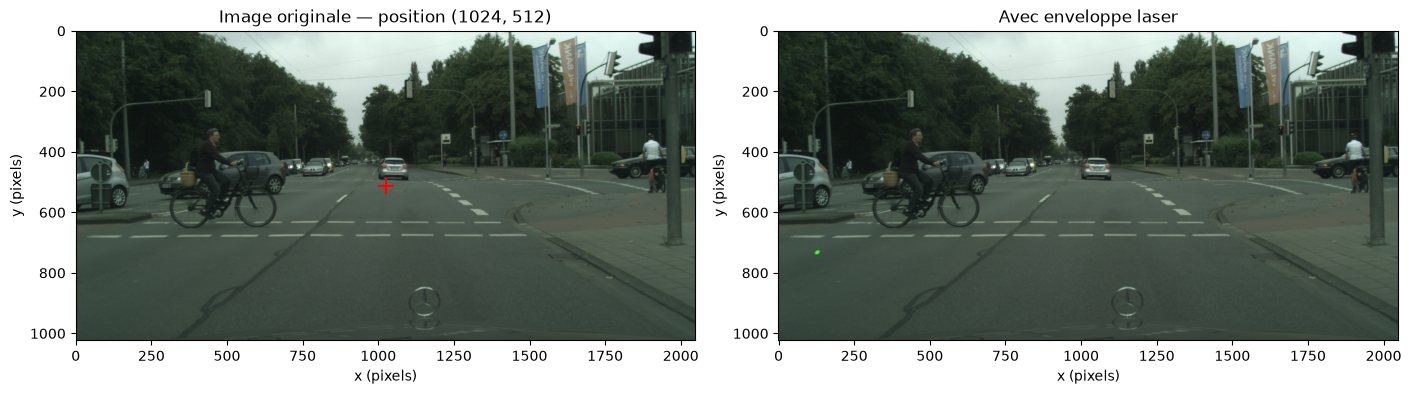

In [7]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    constrained_layout=True,
)

axes[0].imshow(image)
axes[0].plot(
    *position,
    marker="+",
    color="red",
    markersize=12,
    markeredgewidth=1.5,
)
axes[0].set_title(f"Image originale — position {position}")

axes[1].imshow(result)
axes[1].set_title("Avec enveloppe laser")

for ax in axes:
    ax.set_xlabel("x (pixels)")
    ax.set_ylabel("y (pixels)")

plt.show()

In [8]:
def apply_laser_with_white_core(
    image,
    position,
    a=70.0,
    b=40.0,
    angle_deg=30.0,
    p=2.0,
    intensity=0.8,
    white_strength=0.9,
    white_threshold=0.6,
):
    """
    Ajoute le laser, puis un blanchiment progressif de son cœur.

    white_strength : [0, 1]
        Force du blanchiment. 0 = désactivé, 1 = centre blanc.

    white_threshold : [0, 1[
        Seuil relatif de l'enveloppe où commence le blanchiment.
        Plus il est élevé, plus la zone blanche est restreinte.
    """
    if not np.isfinite(white_strength) or not 0 <= white_strength <= 1:
        raise ValueError("white_strength doit être compris entre 0 et 1.")

    if not np.isfinite(white_threshold) or not 0 <= white_threshold < 1:
        raise ValueError("white_threshold doit être compris entre 0 inclus et 1 exclu.")

    result, laser = apply_laser(
        image=image,
        position=position,
        a=a,
        b=b,
        angle_deg=angle_deg,
        p=p,
        intensity=intensity,
    )

    if intensity == 0:
        return result, laser, np.zeros_like(laser)

    relative_intensity = laser / intensity

    transition = np.clip(
        (relative_intensity - white_threshold) / (1 - white_threshold),
        0.0,
        1.0,
    )

    # Smoothstep : transition douce aux deux extrémités.
    smooth_transition = transition**2 * (3 - 2 * transition)
    white_map = white_strength * smooth_transition

    result = (
        result * (1 - white_map[..., None])
        + white_map[..., None]
    )

    return result, laser, white_map

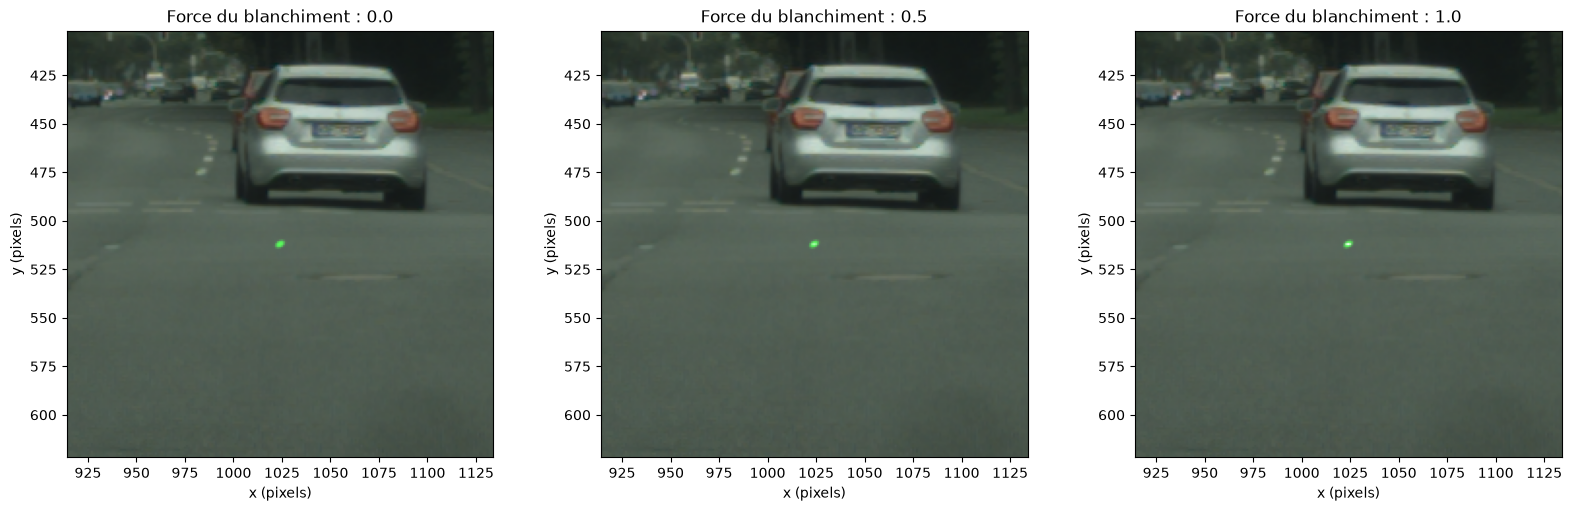

In [9]:
strengths = [0.0, 0.5, 1.0]

fig, axes = plt.subplots(
    1, len(strengths),
    figsize=(16, 5),
    constrained_layout=True,
)

for ax, strength in zip(axes, strengths):
    result, laser, white_map = apply_laser_with_white_core(
        image=image,
        position=position,
        a=3.0,
        b=2.0,
        angle_deg=30.0,
        p=2,
        intensity=0.6,
        white_strength=strength,
        white_threshold=0.9,
    )

    ax.imshow(result)
    ax.set_title(f"Force du blanchiment : {strength}")
    ax.set_xlabel("x (pixels)")
    ax.set_ylabel("y (pixels)")

    # Zoom autour de la marque pour comparer les rendus.
    x0, y0 = position
    margin = 110
    height, width = image.shape[:2]

    ax.set_xlim(max(-0.5, x0 - margin), min(width - 0.5, x0 + margin))
    ax.set_ylim(min(height - 0.5, y0 + margin), max(-0.5, y0 - margin))

plt.show()

In [10]:
from scipy.ndimage import gaussian_filter


def generate_speckle(
    shape,
    speckle_scale=1.2,
    speckle_strength=0.5,
    seed=None
):
    """
    Génère une modulation multiplicative de moyenne spatiale égale à 1.

    speckle_scale :
        Écart-type du filtre sur le champ complexe, en pixels.
        Plus il est élevé, plus les grains sont larges.

    speckle_strength :
        0 = aucune modulation.
        1 = speckle pleinement développé dans le modèle idéal.
    """
    if not np.isfinite(speckle_scale) or speckle_scale <= 0:
        raise ValueError("speckle_scale doit être strictement positif.")

    if not np.isfinite(speckle_strength) or not 0 <= speckle_strength <= 1:
        raise ValueError("speckle_strength doit être compris entre 0 et 1.")

    if speckle_strength == 0:
        return np.ones(shape, dtype=float)

    rng = np.random.default_rng(seed)

    real = gaussian_filter(
        rng.standard_normal(shape),
        sigma=speckle_scale,
        mode="wrap",
    )
    imag = gaussian_filter(
        rng.standard_normal(shape),
        sigma=speckle_scale,
        mode="wrap",
    )

    speckle = real**2 + imag**2
    mean_intensity = speckle.mean()

    if mean_intensity <= 0:
        raise ValueError("Impossible de normaliser le champ de speckle.")

    speckle /= mean_intensity

    return (1.0 - speckle_strength) + speckle_strength * speckle

In [11]:
def generate_bloom(
    contribution,
    bloom_strength=0.5,
    bloom_sigma=8.0,
    bloom_threshold=0.4,
):
    """
    Génère un halo RGB à partir de la contribution laser non écrêtée.
    """
    if not np.isfinite(bloom_strength) or bloom_strength < 0:
        raise ValueError("bloom_strength doit être positif ou nul.")

    if not np.isfinite(bloom_sigma) or bloom_sigma <= 0:
        raise ValueError("bloom_sigma doit être strictement positif.")

    if not np.isfinite(bloom_threshold) or bloom_threshold < 0:
        raise ValueError("bloom_threshold doit être positif ou nul.")

    contribution = np.asarray(contribution, dtype=float)

    # Mesure simple de luminosité adaptée à notre rendu RGB.
    brightness = np.max(contribution, axis=-1)

    # Extraction progressive de la partie dépassant le seuil.
    weight = np.divide(
        np.maximum(brightness - bloom_threshold, 0.0),
        brightness,
        out=np.zeros_like(brightness),
        where=brightness > 0,
    )

    bright_pass = contribution * weight[..., None]

    # Flou spatial uniquement : aucun mélange entre canaux RGB.
    halo = gaussian_filter(
        bright_pass,
        sigma=(bloom_sigma, bloom_sigma, 0),
        mode="constant",
        cval=0.0,
    )

    return bloom_strength * halo

In [12]:
def generate_flare(
    contribution,
    position,
    flare_strength=0.15,
    flare_radius=25.0,
    flare_threshold=0.4,
    ghost_positions=(0.6, 1.2, 1.7),
):
    """
    Génère des reflets fantômes simplifiés.

    contribution : contribution laser RGB avant écrêtage final.
    position : centre du laser (x, y), depuis le coin supérieur gauche.
    """
    if not np.isfinite(flare_strength) or flare_strength < 0:
        raise ValueError("flare_strength doit être positif ou nul.")

    if not np.isfinite(flare_radius) or flare_radius <= 0:
        raise ValueError("flare_radius doit être strictement positif.")

    if not np.isfinite(flare_threshold) or flare_threshold < 0:
        raise ValueError("flare_threshold doit être positif ou nul.")

    ghost_positions = np.asarray(ghost_positions, dtype=float)

    if ghost_positions.ndim != 1 or not np.all(np.isfinite(ghost_positions)):
        raise ValueError("ghost_positions doit être une séquence de valeurs finies.")

    height, width = contribution.shape[:2]
    flare = np.zeros_like(contribution, dtype=float)

    if flare_strength == 0 or len(ghost_positions) == 0:
        return flare

    brightness = np.max(contribution, axis=-1)

    # Mesure robuste de la luminosité près du centre de la marque.
    x0, y0 = map(float, position)
    X, Y = np.meshgrid(np.arange(width), np.arange(height))

    source_region = (X - x0)**2 + (Y - y0)**2 <= 5.0**2
    source_level = np.mean(brightness[source_region])
    activation = max(source_level - flare_threshold, 0.0)

    if activation == 0:
        return flare

    center_x = (width - 1) / 2
    center_y = (height - 1) / 2

    direction_x = center_x - x0
    direction_y = center_y - y0

    flare_color = np.array([0.15, 1.0, 0.15])

    for index, t in enumerate(ghost_positions):
        ghost_x = x0 + t * direction_x
        ghost_y = y0 + t * direction_y

        radius = flare_radius * (1.0 + 0.3 * index)
        attenuation = 1.0 / (1.0 + index)

        radius_squared = (
            ((X - ghost_x) / radius)**2
            + ((Y - ghost_y) / radius)**2
        )

        ghost = np.exp(-2.0 * radius_squared)

        flare += (
            flare_strength
            * activation
            * attenuation
            * ghost[..., None]
            * flare_color
        )

    return flare

In [13]:
def generate_starburst(
    contribution,
    position,
    star_strength=0.25,
    star_rays=6,
    star_length=100.0,
    star_width=1.5,
    star_angle_deg=15.0,
    star_threshold=0.4,
    star_color=(0.75, 1.0, 0.75),
):
    """
    Génère une étoile graphique centrée sur la marque.

    star_rays :
        Nombre total de branches, entier pair.
    star_length :
        Distance en pixels où le profil longitudinal tombe à 1/e.
        Ce n'est pas une longueur de coupure.
    star_width :
        Écart-type transversal en pixels.
    star_angle_deg :
        Orientation antihoraire de la première traînée.
    """
    if (
        not isinstance(star_rays, (int, np.integer))
        or star_rays < 2
        or star_rays % 2 != 0
    ):
        raise ValueError("star_rays doit être un entier pair >= 2.")

    params = np.asarray([
        star_strength,
        star_length,
        star_width,
        star_angle_deg,
        star_threshold,
    ], dtype=float)

    if not np.all(np.isfinite(params)):
        raise ValueError("Les paramètres doivent être finis.")

    if star_strength < 0 or star_threshold < 0:
        raise ValueError("La force et le seuil doivent être positifs ou nuls.")

    if star_length <= 0 or star_width <= 0:
        raise ValueError("La longueur et la largeur doivent être positives.")

    color = np.asarray(star_color, dtype=float)

    if (
        color.shape != (3,)
        or not np.all(np.isfinite(color))
        or np.any((color < 0) | (color > 1))
    ):
        raise ValueError("star_color doit contenir trois valeurs entre 0 et 1.")

    height, width = contribution.shape[:2]
    star = np.zeros_like(contribution, dtype=float)

    if star_strength == 0:
        return star

    x0, y0 = map(float, position)
    X, Y = np.meshgrid(np.arange(width), np.arange(height))

    dx = X - x0
    dy = y0 - Y  # Axe vertical orienté vers le haut.

    # Même principe de déclenchement que pour nos reflets fantômes.
    brightness = np.max(contribution, axis=-1)
    source_region = dx**2 + dy**2 <= 5.0**2

    if not np.any(source_region):
        return star

    source_level = brightness[source_region].mean()
    activation = max(source_level - star_threshold, 0.0)

    if activation == 0:
        return star

    number_of_lines = star_rays // 2
    star_profile = np.zeros((height, width), dtype=float)

    for index in range(number_of_lines):
        angle = (
            np.deg2rad(star_angle_deg)
            + index * np.pi / number_of_lines
        )

        longitudinal = dx * np.cos(angle) + dy * np.sin(angle)
        transverse = -dx * np.sin(angle) + dy * np.cos(angle)

        line = (
            np.exp(-np.abs(longitudinal) / star_length)
            * np.exp(-0.5 * (transverse / star_width)**2)
        )

        star_profile += line

    # Stabilise l'intensité centrale quand le nombre de branches change.
    star_profile /= number_of_lines

    star = (
        star_strength
        * activation
        * star_profile[..., None]
        * color
    )

    return star

In [14]:
def apply_laser_with_speckle(
    image,
    position,
    a=70.0,
    b=40.0,
    angle_deg=30.0,
    p=2.0,
    intensity=0.8,
    white_strength=0.9,
    white_threshold=0.6,
    speckle_strength=0.5,
    speckle_scale=1.2,
    seed=None,
    bloom_strength=0.5,
    bloom_sigma=8.0,
    bloom_threshold=0.4,
    flare_strength=0.15,
    flare_radius=25.0,
    flare_threshold=0.4,
    ghost_positions=(0.6, 1.2, 1.7),
    star_strength=0.25,
    star_rays=6,
    star_length=100.0,
    star_width=1.5,
    star_angle_deg=15.0,
    star_threshold=0.4,
):
    """
    Ajoute une enveloppe laser modulée par du speckle,
    puis applique le blanchiment central existant.

    Retourne :
        result   : image composée
        envelope : enveloppe sans speckle
        laser    : intensité après modulation
        speckle  : modulation multiplicative
        white_map: carte de blanchiment
    """
    if not np.isfinite(white_strength) or not 0 <= white_strength <= 1:
        raise ValueError("white_strength doit être compris entre 0 et 1.")

    if not np.isfinite(white_threshold) or not 0 <= white_threshold < 1:
        raise ValueError(
            "white_threshold doit être compris entre 0 inclus et 1 exclu."
        )

    _, envelope = apply_laser(
        image=image,
        position=position,
        a=a,
        b=b,
        angle_deg=angle_deg,
        p=p,
        intensity=intensity,
    )

    speckle = generate_speckle(
        shape=envelope.shape,
        speckle_scale=speckle_scale,
        speckle_strength=speckle_strength,
        seed=seed,
    )

    laser = envelope * speckle

    # Construction du blanchiment à partir de l'enveloppe lisse.
    if intensity > 0:
        relative_intensity = envelope / intensity

        transition = np.clip(
            (relative_intensity - white_threshold)
            / (1.0 - white_threshold),
            0.0,
            1.0,
        )

        white_map = (
            white_strength
            * transition**2
            * (3.0 - 2.0 * transition)
        )
    else:
        white_map = np.zeros_like(envelope)

    background = np.asarray(image, dtype=float)
    green = np.array([0.0, 1.0, 0.0])

    # Rendu lisse : enveloppe verte puis cœur blanc.
    smooth_result = np.clip(
        background + envelope[..., None] * green,
        0.0,
        1.0,
    )

    smooth_result = (
        smooth_result * (1.0 - white_map[..., None])
        + white_map[..., None]
    )

    # Contribution de la marque uniquement, blanc compris.
    contribution = smooth_result - background

    # Contribution verte et blanche, modulée par le speckle.
    speckled_contribution = contribution * speckle[..., None]

    bloom = generate_bloom(
        contribution=speckled_contribution,
        bloom_strength=bloom_strength,
        bloom_sigma=bloom_sigma,
        bloom_threshold=bloom_threshold,
    )

    flare = generate_flare(
        contribution=speckled_contribution,
        position=position,
        flare_strength=flare_strength,
        flare_radius=flare_radius,
        flare_threshold=flare_threshold,
        ghost_positions=ghost_positions,
    )

    star = generate_starburst(
        contribution=speckled_contribution,
        position=position,
        star_strength=star_strength,
        star_rays=star_rays,
        star_length=star_length,
        star_width=star_width,
        star_angle_deg=star_angle_deg,
        star_threshold=star_threshold,
    )

    result = np.clip(
        background
        + speckled_contribution
        + bloom
        + flare
        + star,
        0.0,
        1.0,
    )

    return result, envelope, laser, speckle, white_map

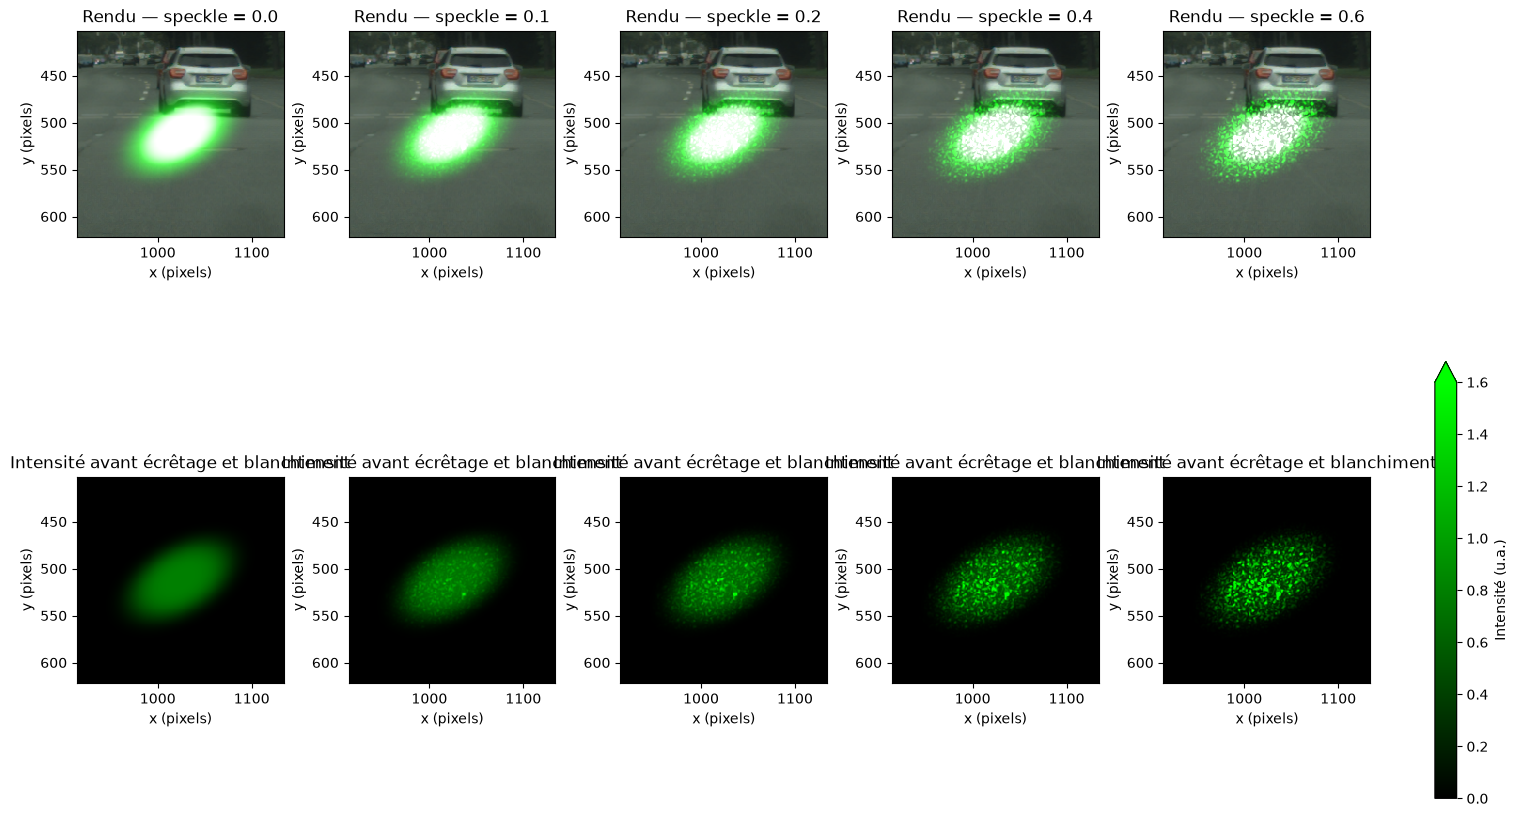

In [15]:
strengths = [0.0, 0.1, 0.2, 0.4, 0.6]

fig, axes = plt.subplots(
    2, len(strengths),
    figsize=(15, 9),
    constrained_layout=True,
)

x0, y0 = position
height, width = image.shape[:2]
margin = 110

for col, strength in enumerate(strengths):
    result, envelope, laser, speckle, white_map = apply_laser_with_speckle(
        image=image,
        position=position,
        a=70.0,
        b=40.0,
        angle_deg=30.0,
        p=2.0,
        intensity=0.8,
        white_strength=0.9,
        white_threshold=0.6,
        speckle_strength=strength,
        speckle_scale=1.2,
        seed=42,
    )

    axes[0, col].imshow(result, interpolation="nearest")
    axes[0, col].set_title(f"Rendu — speckle = {strength}")

    intensity_plot = axes[1, col].imshow(
        laser,
        cmap=laser_cmap,
        vmin=0.0,
        vmax=1.6,
        interpolation="nearest",
    )
    axes[1, col].set_title("Intensité avant écrêtage et blanchiment")

    for row in range(2):
        ax = axes[row, col]
        ax.set_xlim(
            max(-0.5, x0 - margin),
            min(width - 0.5, x0 + margin),
        )
        ax.set_ylim(
            min(height - 0.5, y0 + margin),
            max(-0.5, y0 - margin),
        )
        ax.set_xlabel("x (pixels)")
        ax.set_ylabel("y (pixels)")

fig.colorbar(
    intensity_plot,
    ax=axes[1, :].tolist(),
    label="Intensité (u.a.)",
    extend="max",
)

plt.show()

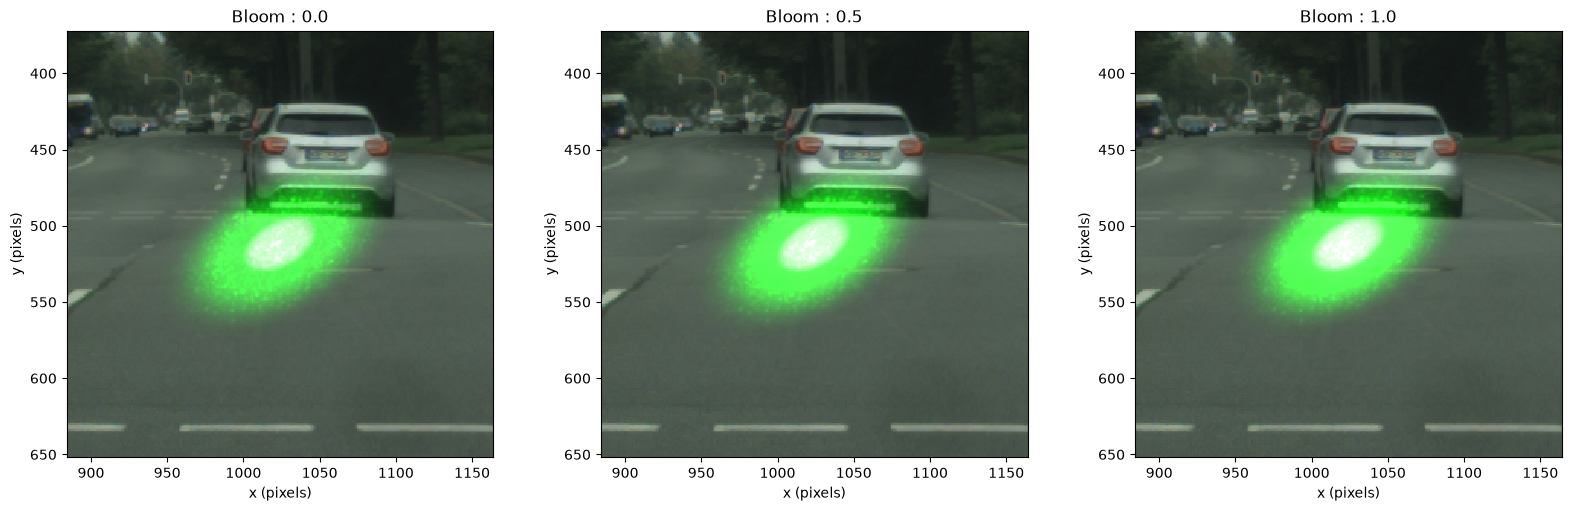

In [16]:
strengths = [0.0, 0.5, 1.0]

fig, axes = plt.subplots(
    1, len(strengths),
    figsize=(16, 5),
    constrained_layout=True,
)

x0, y0 = position
height, width = image.shape[:2]
margin = 140

for ax, strength in zip(axes, strengths):
    result, *_ = apply_laser_with_speckle(
        image=image,
        position=position,
        a=70.0,
        b=40.0,
        angle_deg=30.0,
        p=2.0,
        intensity=0.8,
        white_strength=0.7,
        white_threshold=0.95,
        speckle_strength=0.1,
        speckle_scale=1.2,
        seed=42,
        bloom_strength=strength,
        bloom_sigma=8.0,
        bloom_threshold=0.4,
    )

    ax.imshow(result, interpolation="nearest")
    ax.set_title(f"Bloom : {strength}")

    ax.set_xlim(
        max(-0.5, x0 - margin),
        min(width - 0.5, x0 + margin),
    )
    ax.set_ylim(
        min(height - 0.5, y0 + margin),
        max(-0.5, y0 - margin),
    )

    ax.set_xlabel("x (pixels)")
    ax.set_ylabel("y (pixels)")

plt.show()

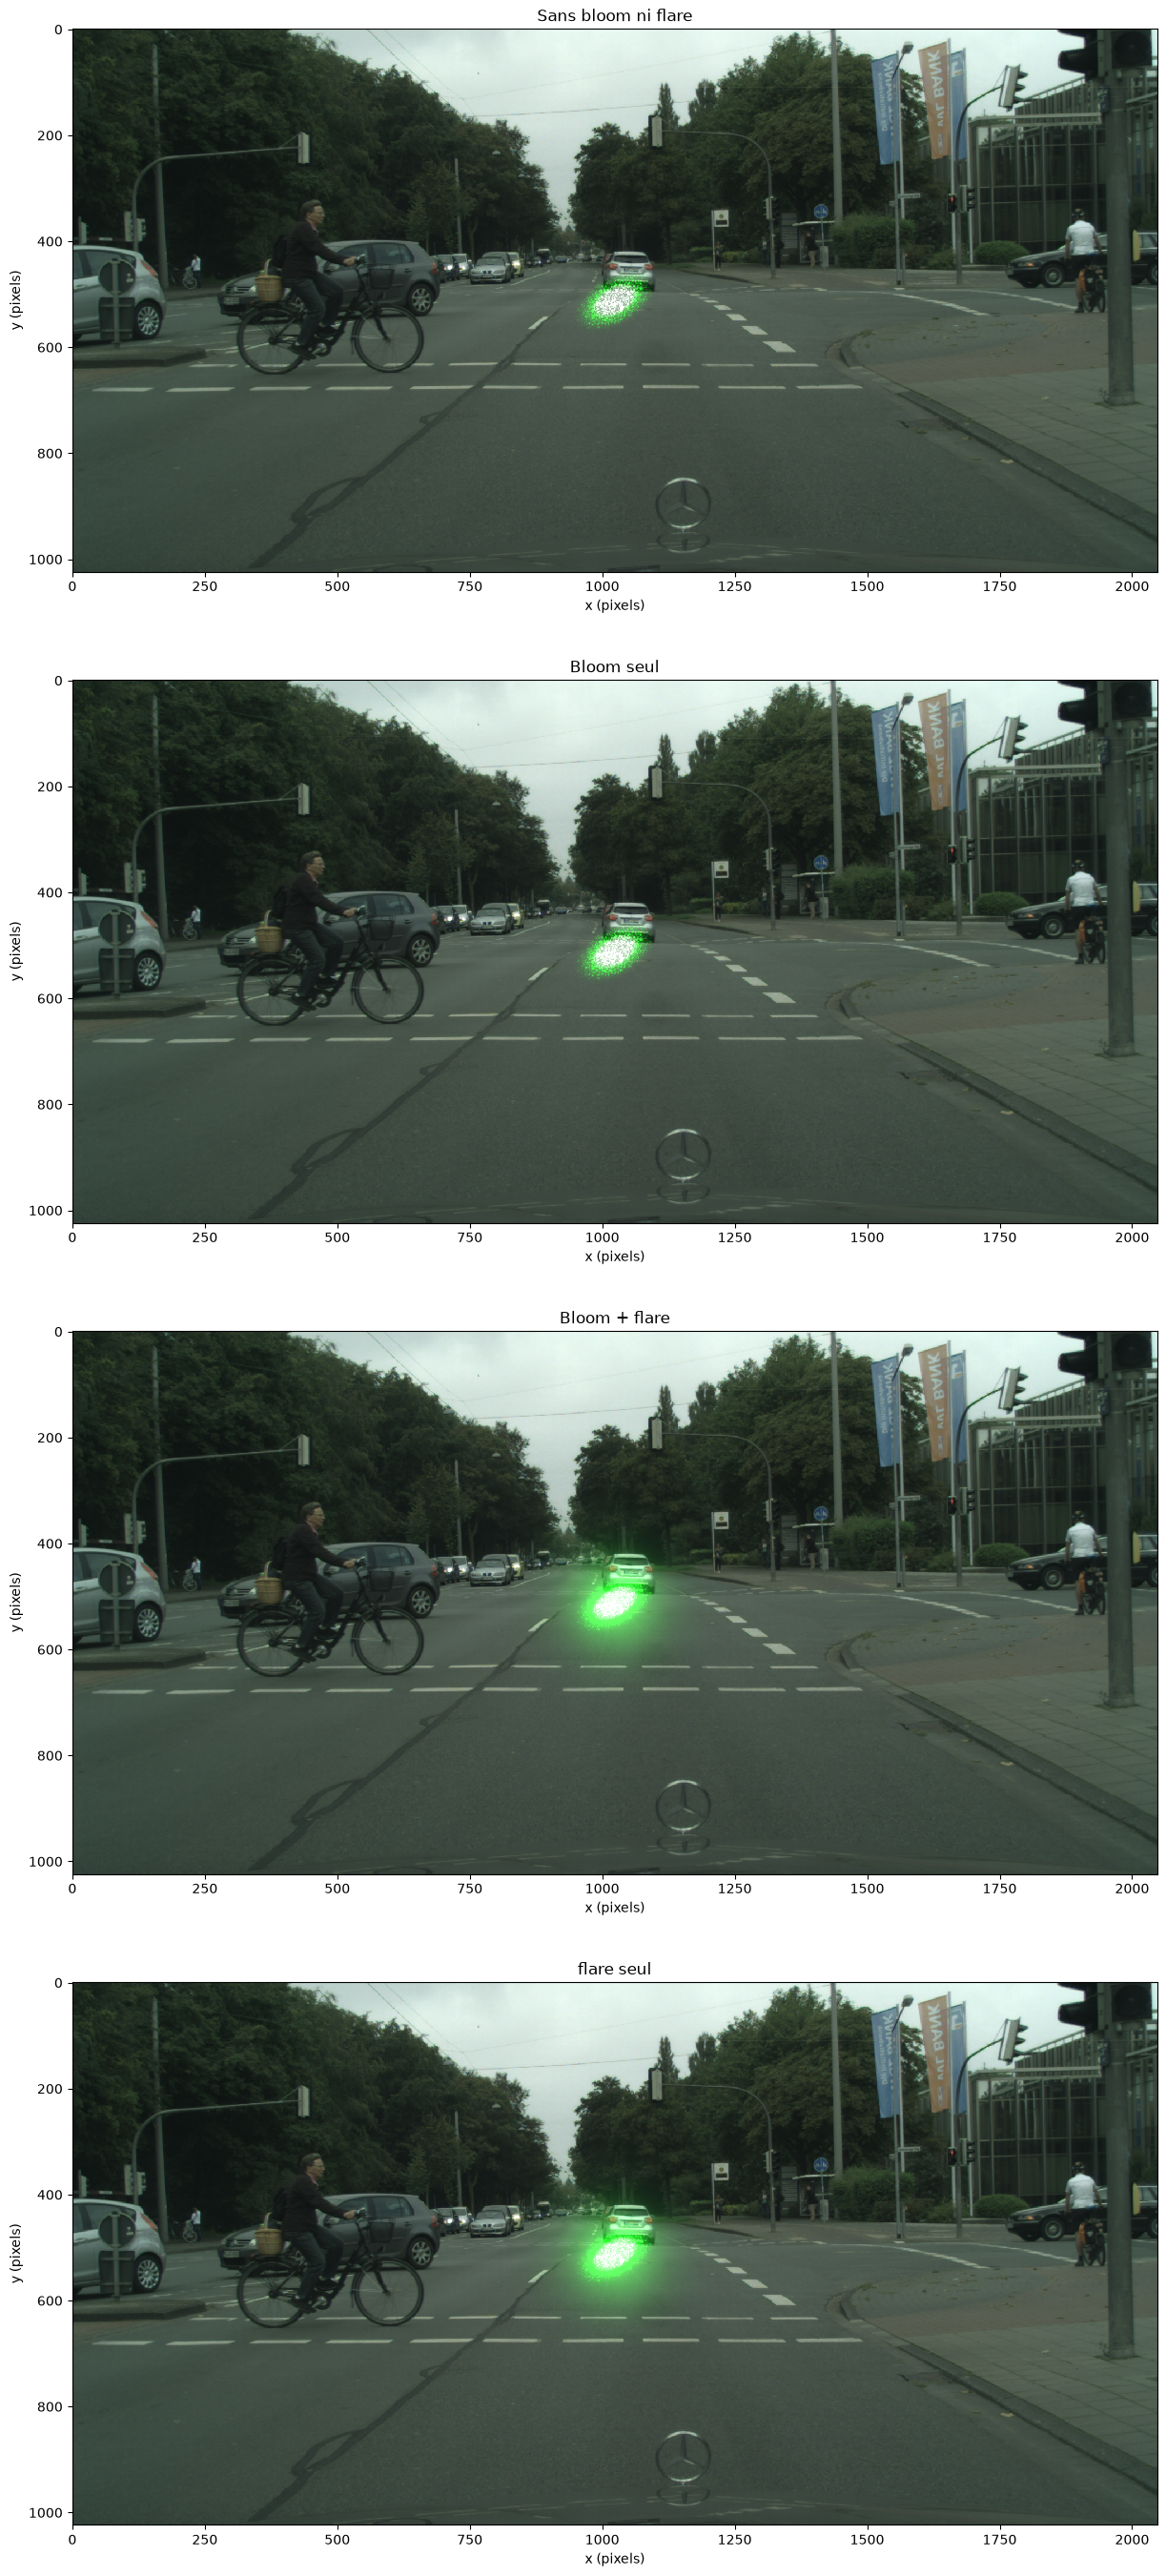

In [17]:
settings = [
    ("Sans bloom ni flare", 0.0, 0.0),
    ("Bloom seul", 0.5, 0.0),
    ("Bloom + flare", 0.5, 1.0),
    ("flare seul", 0.0, 1.0)
]

fig, axes = plt.subplots(
    4, 1,
    figsize=(17, 34),
    # constrained_layout=True,
)

for ax, (title, bloom_strength, flare_strength) in zip(axes, settings):
    result, *_ = apply_laser_with_speckle(
        image=image,
        position=position,
        a=70.0,
        b=40.0,
        angle_deg=30.0,
        p=2.0,
        intensity=0.8,
        white_strength=0.9,
        white_threshold=0.6,
        speckle_strength=0.5,
        speckle_scale=1.2,
        seed=42,
        bloom_strength=bloom_strength,
        bloom_sigma=8.0,
        bloom_threshold=0.4,
        flare_strength=flare_strength,
        flare_radius=100,
        flare_threshold=0.4,
    )

    ax.imshow(result, interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("x (pixels)")
    ax.set_ylabel("y (pixels)")

plt.show()

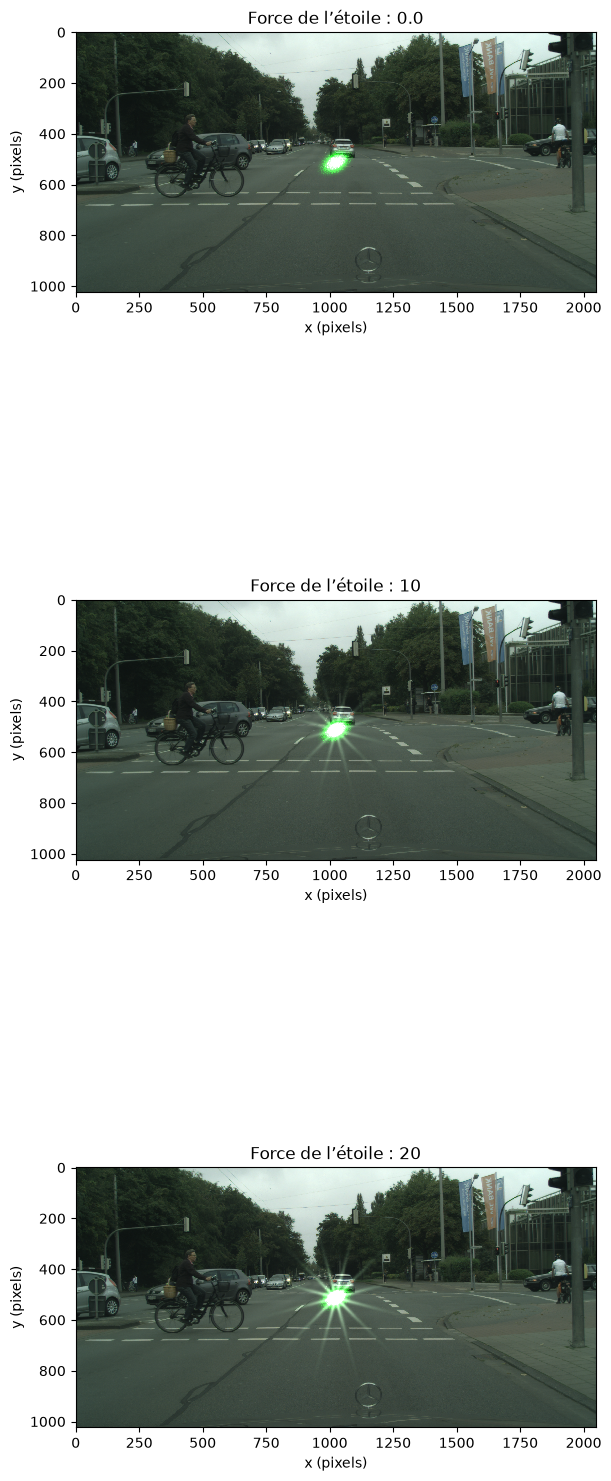

In [29]:
strengths = [0.0, 10, 20]

fig, axes = plt.subplots(
    len(strengths), 1,
    figsize=(6, 17),
    constrained_layout=True,
)

for ax, strength in zip(axes, strengths):
    result, *_ = apply_laser_with_speckle(
        image=image,
        position=position,
        a=70.0,
        b=40.0,
        angle_deg=30.0,
        p=2.0,
        intensity=0.8,
        white_strength=0.9,
        white_threshold=0.6,
        speckle_strength=0.5,
        speckle_scale=1.2,
        seed=42,
        bloom_strength=0.5,
        bloom_sigma=8.0,
        bloom_threshold=0.4,
        flare_strength=5,
        flare_radius=25.0,
        flare_threshold=0.4,
        star_strength=strength,
        star_rays=12,
        star_length=70.0,
        star_width=5,
        star_angle_deg=15.0,
        star_threshold=0.4,
    )

    ax.imshow(result, interpolation="nearest")
    ax.set_title(f"Force de l’étoile : {strength}")
    ax.set_xlabel("x (pixels)")
    ax.set_ylabel("y (pixels)")

plt.show()